In [2]:
import torch
from torch import nn
import pandas as pd
import random
import ast

In [3]:
## tpr_df = pd.read_csv("wo_bos_eos/no_sos_eos_attention_gru_copy_data.csv")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)
# print(len(tpr_df))

df = pd.read_csv("num_dataset_10.csv")
df['source'] = df['source'].apply(lambda x: ast.literal_eval(x))
df['target'] = df['target'].apply(lambda x: ast.literal_eval(x))

# df_sorted = df.sort_values(by='source', key=lambda col: col.map(len))
model_size = 128

batch_size = 128
print(model_size) 

cuda
128


In [4]:
left_role = 0
right_role = 1
def right_recurse(lst):
    if not lst:
        return []
    
    batch_size = lst[0].shape[0]
    tensors = [[x, torch.full((batch_size,), left_role, device = device)] for x in lst[:-1]]
    
    acc = lst[-1]
    for t in reversed(tensors):
        acc = [t, [acc, torch.full((batch_size,), right_role, device = device)]]
    return acc

def left_recurse(lst):
    if not lst:
        return []
    
    batch_size = lst[0].shape[0]
    tensors = [[x, torch.full((batch_size,), right_role, device = device)] for x in lst[1:]]
    
    acc = lst[0]
    for t in tensors:
        acc = [[acc, torch.full((batch_size,), left_role, device = device)], t]
    return acc

In [5]:
def collate_lists(*lists):
    """
    Takes multiple lists of integers of the same length and returns
    a list of tensors, one per position across the batch.
    
    Example: collate_lists([8,3,6,2], [1,5,7,4], [2,2,1,6])
    Returns: [tensor([8,1,2]), tensor([3,5,7]), tensor([6,7,1]), tensor([2,4,6])]
    """
    assert len(set(len(l) for l in lists)) == 1, "All lists must be the same length"
    
    return [torch.tensor([lst[i] for lst in lists]) for i in range(len(lists[0]))]

In [6]:
sources = df["source"].tolist()
targets = df["target"].tolist()

# --- Bucket batching: group sequences by length, batch within each bucket ---
from collections import defaultdict

buckets = defaultdict(list)  # seq_len -> list of (source, target) pairs

for src, trg in zip(sources, targets):
    buckets[len(src)].append((src, trg))

In [7]:
print(buckets.keys())

dict_keys([6, 5, 4, 3, 2, 1, 7, 8, 9])


In [8]:
src_batches = []
trg_batches = []

for seq_len in sorted(buckets.keys()):
    pairs = buckets[seq_len]
    # Batch within this length bucket; last batch may be smaller — that's okay
    for i in range(0, len(pairs), batch_size):
        # If i + batch_size is out of bounds, it just goes to the end of the list
        chunk = pairs[i:i + batch_size]
        src_batch = [p[0] for p in chunk]
        trg_batch = [p[1] for p in chunk]

        # collate_lists expects *lists unpacked, where each list is one sequence's tokens
        # so we unpack the source sequences — gives one tensor per position across the batch
        collated = collate_lists(*src_batch)     # list of tensors, each (batch,)
        nested   = right_recurse(collated)
        # nested   = left_recurse(collated)

        src_batches.append(nested)
        trg_batches.append(trg_batch)

# 80/10/10 split at batch level
n       = len(src_batches)
n_train = int(0.8 * n)
n_val   = int(0.1 * n)
# test: remainder

combined = list(zip(src_batches, trg_batches))
random.shuffle(combined)
src_batches, trg_batches = zip(*combined)

In [9]:
def get_recursive_batch_size(x):
    if isinstance(x[0], list):
        return get_recursive_batch_size(x[0])
    return x[0].shape[0]
    
class RTPREncode(nn.Module):
    def __init__(self, nfillers, nroles, filler_size, role_size, model_size):
        super(RTPREncode, self).__init__()
        self.fillers = nn.Embedding(nfillers, filler_size)
        self.roles = nn.Embedding(nroles, role_size)
        self.filler_size = filler_size
        self.role_size = role_size
        self.model_size = model_size
        # self.dropout = nn.Dropout(0.4)
        self.w = torch.nn.Parameter(torch.randn(filler_size, filler_size*role_size)*0.01)
        self.wo = torch.nn.Parameter(torch.randn(model_size, filler_size)*0.01)

    def forward(self, x):
        cur_batch_size = get_recursive_batch_size(x)
        
        result = torch.zeros(cur_batch_size, self.filler_size, self.role_size, device=self.w.device)
    
        for pair in x:
            filler = pair[0]
            role = pair[1].to(device)
            
            if isinstance(filler, list):
                filler = self(filler)
            else:
                filler = self.fillers(filler.to(device))
            
            role = self.roles(role)
            result += torch.einsum("bf,br->bfr", filler, role)
        
        result = result.view(cur_batch_size, -1)
        result = torch.einsum("ij,bj->bi", self.w, result) 
        return result

In [10]:
class Encoder(nn.Module):
    def __init__(self, input_size, embed_size, hidden_size, num_layers):
        super(Encoder, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.embedding = nn.Embedding(input_size, embed_size)
        self.gru = nn.GRU(embed_size, hidden_size, num_layers, batch_first=True)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        #Expands a token to dim embed_size, based on learned embeddings
        embedding = self.dropout(self.embedding(x))

        #outputs: hidden state at every timestep, shape (batch, seq_len, hidden_size)
        #         this is what attention will attend over
        #hidden:  final hidden state, shape (num_layers, batch, hidden_size)
        #         still used to initialize the decoder's hidden state
        outputs, hidden = self.gru(embedding)

        return outputs, hidden
        
class Attention(nn.Module):
    def __init__(self, hidden_size):
        super(Attention, self).__init__()
        #Projects [decoder_hidden ; encoder_output] -> a scalar-ish energy vector
        self.attn = nn.Linear(hidden_size * 2, hidden_size)
        self.v = nn.Linear(hidden_size, 1, bias=False)

    def forward(self, decoder_hidden, encoder_outputs, mask=None):
        # decoder_hidden:  (batch, hidden_size)          - last layer's hidden state
        # encoder_outputs: (batch, src_len, hidden_size)
        # mask:            (batch, src_len) bool, True where it's a real (non-pad) token
        src_len = encoder_outputs.shape[1]

        #Repeat decoder hidden state src_len times so it can be compared against
        #every encoder timestep: (batch, src_len, hidden_size)
        hidden_repeated = decoder_hidden.unsqueeze(1).repeat(1, src_len, 1)

        #Concatenate along the feature dim and squash through a linear + tanh
        energy = torch.tanh(self.attn(torch.cat((hidden_repeated, encoder_outputs), dim=2)))

        #Collapse hidden_size -> 1, giving one score per encoder timestep
        attention = self.v(energy).squeeze(2)  # (batch, src_len)

        #Prevent attending to <pad> positions
        if mask is not None:
            attention = attention.masked_fill(~mask, -1e10)

        weights = torch.softmax(attention, dim=1)  # (batch, src_len)

        #Weighted sum of encoder outputs -> context vector (batch, hidden_size)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)

        return context, weights

class Decoder(nn.Module):
    #Input and output sizes are the same here b/c both use same vocab space
    def __init__(self, input_size, embed_size, hidden_size, output_size, num_layers):
        super(Decoder, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.embedding = nn.Embedding(input_size, embed_size)
        self.attention = Attention(hidden_size)

        #GRU input is now [embedded token ; attention context], hence embed_size + hidden_size
        self.gru = nn.GRU(embed_size + hidden_size, hidden_size, num_layers, batch_first=True)
        self.dropout = nn.Dropout(0.2)

        #fc takes [gru output ; context ; embedded token] -> vocab_size, giving it direct
        #access to the context vector rather than forcing everything through the GRU
        self.fc = nn.Linear(hidden_size * 2 + embed_size, output_size)

    def forward(self, x, hidden, encoder_outputs, mask=None):
        #Converts shape of x from (batch_size) to (batch_size, 1)
        x = x.unsqueeze(1)
        #Converts shape now to (batch_size, 1, embed_size)
        embedding = self.dropout(self.embedding(x))

        #Attend over encoder_outputs using the top layer's current hidden state
        context, attn_weights = self.attention(hidden[-1], encoder_outputs, mask)

        #Feed [embedded token ; context] into the GRU at this timestep
        gru_input = torch.cat((embedding, context.unsqueeze(1)), dim=2)
        outputs, hidden = self.gru(gru_input, hidden)

        #Squeeze the seq_len=1 dimension back out
        outputs = outputs.squeeze(1)
        embedding = embedding.squeeze(1)

        #Combine GRU output, context, and embedded input before the final projection
        predictions = self.fc(torch.cat((outputs, context, embedding), dim=1))

        return predictions, hidden, attn_weights

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super(Seq2Seq, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, source, target, teacher_force_ratio):
        batch_size = source.shape[0]
        target_len = source.shape[1]

        #Tensor of zeros with shape (batch_size, target_len, vocab_size), will gradually be filled in by the decoder
        #BN: Vocab_size != Embedding_Size
        outputs = torch.zeros(batch_size, target_len, vocab_size).to(device)

        #Mask out <pad> positions in the source so attention can't look at them
        mask = (source != pad_val)

        #All encoder hidden states (for attention) + final hidden state (to seed the decoder)
        encoder_outputs, hidden = self.encoder(source)

        #Effectively the <sos> token
        # x = target[:, 0]
        x = torch.full((batch_size,), sos_val, dtype=torch.long).to(device)

        for t in range(1, target_len):
            output, hidden, _ = self.decoder(x, hidden, encoder_outputs, mask)
            #Fill in the outputs variable
            outputs[:, t] = output

            #Chooses the one with the highest probability
            best_guess = output.argmax(1)

            #Using random to ensure teacher forcing is applied only a certain percentage of the time
            if random.random() < teacher_force_ratio:
                x = target[:, t]
            else:
                x = best_guess

        return outputs

In [52]:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tpr_model = RTPREncode(11, 2, 64, 64, model_size).to(device)

encoder_embedding_size = 64
decoder_embedding_size = 64
hidden_size = 128
num_layers = 1
vocab_size = 12
pad_val = 11

#Model hyperparameters
encoder_net = Encoder(vocab_size, encoder_embedding_size, hidden_size, num_layers).to(device)
decoder_net = Decoder(vocab_size, decoder_embedding_size, hidden_size, vocab_size, num_layers).to(device)

s2s_model = Seq2Seq(encoder_net, decoder_net).to(device)
s2s_model.load_state_dict(torch.load("wo_bos_eos/no_sos_bos_attention_reversal.pt", weights_only=True, map_location=torch.device('cuda')))
tpr_model.load_state_dict(torch.load("no_sos_bos_attention_right_reversal.pt", weights_only=True, map_location=torch.device('cuda')))

<All keys matched successfully>

Bucket size: 10000
Full sequence accuracy: 0.0


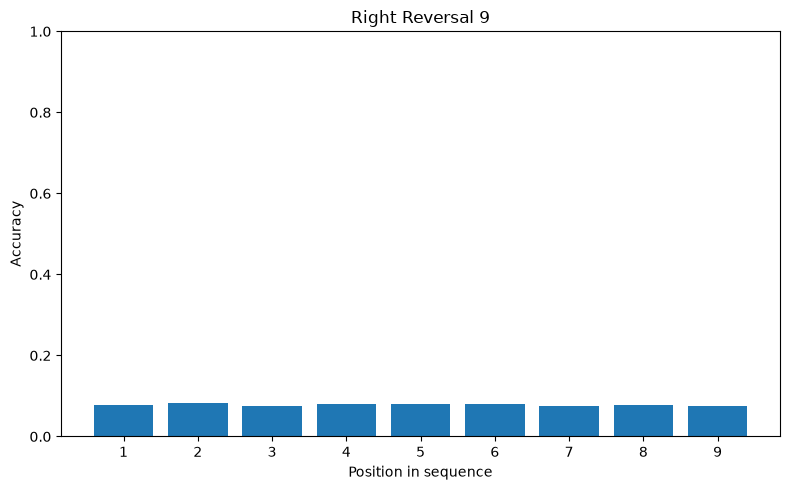

In [61]:
import matplotlib.pyplot as plt

test_len = 9

with torch.no_grad():
    tpr_model.eval()
    s2s_model.eval()

    eval_batch_size = 256
    go_val = 10
    total = 0
    correct = 0
    position_correct = None  # initialized once we know sequence length L

    pairs = buckets[test_len]
    print(f"Bucket size: {len(pairs)}")
    for start in range(0, len(pairs), eval_batch_size):
        chunk = pairs[start:start + eval_batch_size]
        B = len(chunk)
        total += B

        src_batch = [p[0] for p in chunk]
        test_seq = torch.tensor(src_batch, dtype=torch.long, device=device)
        mask = (test_seq != pad_val)
        L = test_seq.size(1)

        if position_correct is None:
            position_correct = torch.zeros(L, dtype=torch.long, device=device)

        go_col = torch.full((B, 1), go_val, dtype=torch.long, device=device)

        encoder_outputs = []
        for i in range(L):
            current = torch.cat((go_col, test_seq[:, :i + 1]), dim=1)
            encoding = tpr_model(left_recurse(collate_lists(*current)))
            hidden_i = torch.matmul(encoding, tpr_model.wo.T)
            encoder_outputs.append(hidden_i)

        hidden = encoder_outputs[-1].unsqueeze(0)
        encoder_outputs = torch.stack(encoder_outputs, dim=1)

        decoder_input = torch.full((B,), go_val, dtype=torch.long, device=device)
        predicted = torch.zeros((B, L), dtype=torch.long, device=device)

        for step in range(L):
            prediction, hidden, attn_weights = s2s_model.decoder(
                decoder_input, hidden, encoder_outputs, mask
            )
            best_guess = prediction.argmax(dim=1)
            predicted[:, step] = best_guess
            decoder_input = best_guess

        #Reversal
        matches = (predicted == torch.flip(test_seq, dims=[1]))
        #Copy
        # matches = (predicted == test_seq)
        position_correct += matches.sum(dim=0)          # per-position hits
        correct += matches.all(dim=1).sum().item()       # full-sequence hits

    positional_accuracy = (position_correct.float() / total).cpu().numpy()
    full_seq_accuracy = correct / total

print(f"Full sequence accuracy: {full_seq_accuracy}")

# --- plot ---
positions = list(range(1, len(positional_accuracy) + 1))
plt.figure(figsize=(8, 5))
plt.bar(positions, positional_accuracy)
plt.xlabel("Position in sequence")
plt.ylabel("Accuracy")
plt.title(f"Right Reversal {test_len}")
plt.ylim(0, 1)
plt.xticks(positions)
plt.tight_layout()
plt.show()